In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TABELAS = Path("../resultados/tabelas")
FIGURAS = Path("../resultados/figuras")
PROC = Path("../dados/processados")
FIGURAS.mkdir(parents=True, exist_ok=True)

# Padrão visual único para todas as figuras.
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.5,
})

# Paleta em tons de cinza distinguíveis também em impressão monocromática.
CINZA_ESCURO = "#333333"
CINZA_CLARO = "#BBBBBB"

def salvar(fig, nome):
    caminho = FIGURAS / f"{nome}.png"
    fig.savefig(caminho)
    print(f"salvo: {caminho.name}")

In [2]:
res_val = pd.read_csv(TABELAS / "resultados_validacao.csv", index_col=0)
res_teste = pd.read_csv(TABELAS / "resultados_teste_independente.csv", index_col=0)

ORDEM = ["Regressão Logística", "Árvore de Decisão", "Random Forest", "XGBoost"]
res_val = res_val.reindex(ORDEM)
res_teste = res_teste.reindex(ORDEM)

print(res_val[["f1"]].round(4).to_string())
print(res_teste[["f1", "roc_auc"]].round(4).to_string())

                         f1
modelo                     
Regressão Logística  0.9951
Árvore de Decisão    0.9957
Random Forest        0.9969
XGBoost              0.9970
                         f1  roc_auc
modelo                              
Regressão Logística  0.6650   0.6547
Árvore de Decisão    0.6651   0.5013
Random Forest        0.6650   0.5010
XGBoost              0.6655   0.6339


In [3]:
y_val = pd.read_csv(PROC / "y_val.csv", index_col=0)["y"]
y_teste = pd.read_csv(PROC / "y_teste.csv", index_col=0)["y"]

## Figura 1 - Desempenho interno versus externo

Esta é a figura central do trabalho: contrasta o F1 obtido na validação
interna com o F1 no conjunto independente, para os quatro classificadores.

salvo: fig1_desempenho_interno_externo.png


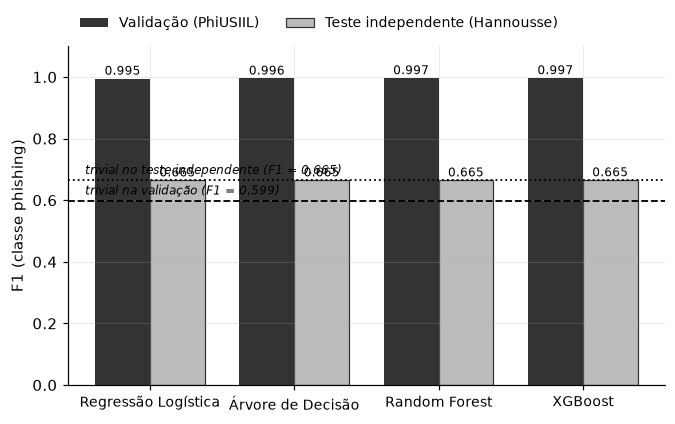

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))

x = np.arange(len(ORDEM))
largura = 0.38

ax.bar(x - largura/2, res_val["f1"], largura,
       label="Validação (PhiUSIIL)", color=CINZA_ESCURO)
ax.bar(x + largura/2, res_teste["f1"], largura,
       label="Teste independente (Hannousse)", color=CINZA_CLARO,
       edgecolor=CINZA_ESCURO, linewidth=0.8)

# Linhas do classificador trivial (prever sempre a classe positiva), uma por
# conjunto: a proporção de phishing difere entre validação e teste.
f1_trivial_val = 2 * y_val.mean() / (1 + y_val.mean())
f1_trivial_teste = 2 * y_teste.mean() / (1 + y_teste.mean())

ax.axhline(f1_trivial_val, color="black", linestyle="--", linewidth=1.2)
ax.text(-0.45, f1_trivial_val + 0.02,
        f"trivial na validação (F1 = {f1_trivial_val:.3f})",
        fontsize=8, ha="left", style="italic")

ax.axhline(f1_trivial_teste, color="black", linestyle=":", linewidth=1.2)
ax.text(-0.45, f1_trivial_teste + 0.02,
        f"trivial no teste independente (F1 = {f1_trivial_teste:.3f})",
        fontsize=8, ha="left", style="italic")

for i, (v, t) in enumerate(zip(res_val["f1"], res_teste["f1"])):
    ax.text(i - largura/2, v + 0.012, f"{v:.3f}", ha="center", fontsize=8)
    ax.text(i + largura/2, t + 0.012, f"{t:.3f}", ha="center", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(ORDEM, fontsize=9)
ax.set_ylabel("F1 (classe phishing)")
ax.set_ylim(0, 1.10)
ax.legend(frameon=False, fontsize=9, ncol=2,
          loc="lower left", bbox_to_anchor=(0, 1.01))

salvar(fig, "fig1_desempenho_interno_externo")
plt.show()

## Figura 2 - Distribuição do comprimento do caminho nas URLs legítimas


Evidência do viés de coleta: compara a distribuição de `path_length` entre as
URLs da classe legítima de cada conjunto de dados.

In [5]:
X_val = pd.read_csv(PROC / "X_val.csv", index_col=0)
X_teste = pd.read_csv(PROC / "X_teste.csv", index_col=0)

leg_phiusiil = X_val.loc[y_val.values == 0, "path_length"]
leg_hannousse = X_teste.loc[y_teste.values == 0, "path_length"]

print(f"PhiUSIIL  legítimas: n={len(leg_phiusiil):,}  "
      f"média={leg_phiusiil.mean():.2f}  máx={leg_phiusiil.max()}")
print(f"Hannousse legítimas: n={len(leg_hannousse):,}  "
      f"média={leg_hannousse.mean():.2f}  máx={leg_hannousse.max()}")

PhiUSIIL  legítimas: n=26,970  média=0.00  máx=0
Hannousse legítimas: n=5,713  média=20.17  máx=225


salvo: fig2_distribuicao_path_length.png


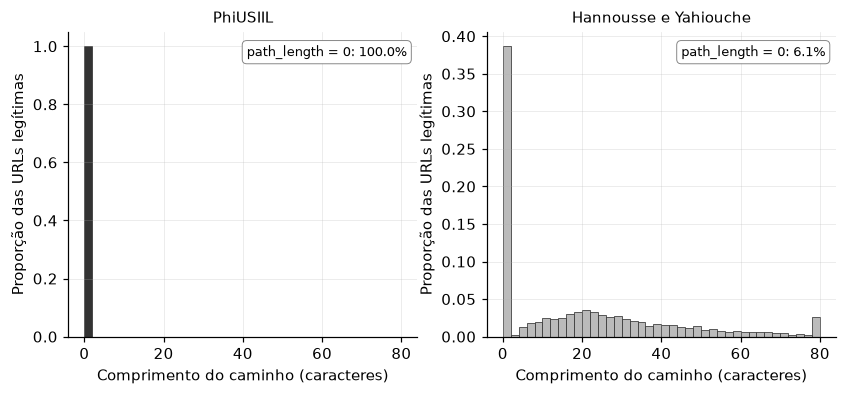

In [6]:
# Eixos verticais independentes e escala em proporção: os dois conjuntos têm
# tamanhos muito diferentes, e uma escala compartilhada em contagem absoluta
# tornaria o painel do Hannousse ilegível.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6))

limite = 80
bins = np.linspace(0, limite, 41)

for ax, dados, titulo, cor in [
    (ax1, leg_phiusiil, "PhiUSIIL", CINZA_ESCURO),
    (ax2, leg_hannousse, "Hannousse e Yahiouche", CINZA_CLARO),
]:
    pesos = np.ones(len(dados)) / len(dados)
    ax.hist(dados.clip(upper=limite), bins=bins, weights=pesos, color=cor,
            edgecolor=CINZA_ESCURO, linewidth=0.5)
    ax.set_xlabel("Comprimento do caminho (caracteres)")
    ax.set_title(titulo, fontsize=10)
    prop_zero = (dados == 0).mean()
    ax.text(0.97, 0.92, f"path_length = 0: {prop_zero:.1%}",
            transform=ax.transAxes, ha="right", fontsize=8.5,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                      edgecolor="gray", linewidth=0.6))

ax1.set_ylabel("Proporção das URLs legítimas")
ax2.set_ylabel("Proporção das URLs legítimas")

salvar(fig, "fig2_distribuicao_path_length")
plt.show()

## Figura 3 - Matrizes de confusão no conjunto independente


Torna visível a natureza do colapso: o recall da classe phishing permanece
alto enquanto a identificação da classe legítima é praticamente nula.

salvo: fig3_matrizes_confusao.png


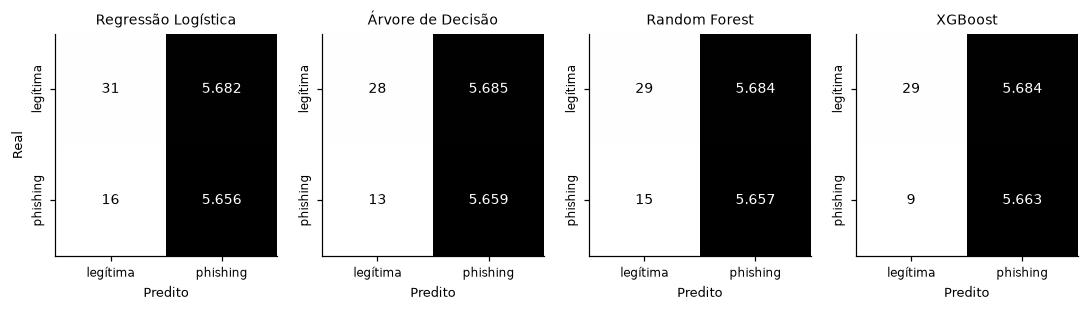

In [7]:
fig, eixos = plt.subplots(1, 4, figsize=(12, 3.2))

for ax, modelo in zip(eixos, ORDEM):
    linha = res_teste.loc[modelo]
    matriz = np.array([[linha["vn"], linha["fp"]],
                       [linha["fn"], linha["vp"]]], dtype=int)
    proporcoes = matriz / matriz.sum(axis=1, keepdims=True)

    ax.imshow(proporcoes, cmap="Greys", vmin=0, vmax=1)

    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matriz[i, j]:,}".replace(",", "."),
                    ha="center", va="center", fontsize=9,
                    color="white" if proporcoes[i, j] > 0.5 else "black")

    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["legítima", "phishing"], fontsize=8)
    ax.set_yticklabels(["legítima", "phishing"], fontsize=8, rotation=90, va="center")
    ax.set_title(modelo, fontsize=9)
    ax.set_xlabel("Predito", fontsize=8.5)
    ax.grid(False)

eixos[0].set_ylabel("Real", fontsize=8.5)

salvar(fig, "fig3_matrizes_confusao")
plt.show()

## Figura 4 - Interpretabilidade

> Escreva a legenda ABNT desta figura.

Os dois modelos são retreinados aqui com a mesma semente usada no notebook 02,
o que reproduz exatamente os estimadores avaliados. A Regressão Logística
fornece coeficientes com sinal e direção; o Random Forest fornece importância
por redução de impureza, que é sempre positiva e não indica direção.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X_tr = pd.read_csv(PROC / "X_tr.csv", index_col=0)
y_tr = pd.read_csv(PROC / "y_tr.csv", index_col=0)["y"]

SEMENTE = 42

lr = Pipeline([
    ("escala", StandardScaler()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=2000,
                               random_state=SEMENTE)),
]).fit(X_tr, y_tr)

rf = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                            random_state=SEMENTE, n_jobs=1).fit(X_tr, y_tr)

coeficientes = pd.Series(lr[-1].coef_[0], index=X_tr.columns)
importancias = pd.Series(rf.feature_importances_, index=X_tr.columns)
print("modelos retreinados")

modelos retreinados


salvo: fig4_interpretabilidade.png


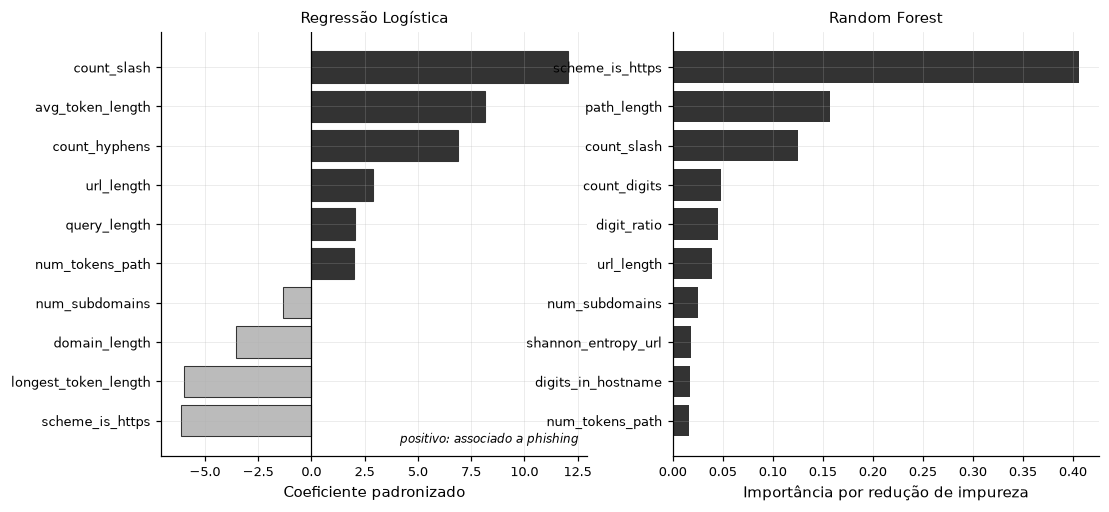

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

# Regressão Logística: dez maiores coeficientes em valor absoluto.
topo_lr = coeficientes.reindex(
    coeficientes.abs().sort_values(ascending=False).index
).head(10).sort_values()

cores = [CINZA_ESCURO if v > 0 else CINZA_CLARO for v in topo_lr]
ax1.barh(topo_lr.index, topo_lr.values, color=cores,
         edgecolor=CINZA_ESCURO, linewidth=0.7)
ax1.axvline(0, color="black", linewidth=0.8)
ax1.set_xlabel("Coeficiente padronizado")
ax1.set_title("Regressão Logística", fontsize=10)
ax1.tick_params(labelsize=8.5)
ax1.text(0.98, 0.03,
         "positivo: associado a phishing",
         transform=ax1.transAxes, ha="right", fontsize=8, style="italic")

# Random Forest: dez maiores importâncias.
topo_rf = importancias.sort_values(ascending=False).head(10).sort_values()
ax2.barh(topo_rf.index, topo_rf.values, color=CINZA_ESCURO)
ax2.set_xlabel("Importância por redução de impureza")
ax2.set_title("Random Forest", fontsize=10)
ax2.tick_params(labelsize=8.5)

salvar(fig, "fig4_interpretabilidade")
plt.show()

In [10]:
# Tabela de apoio: os dez atributos mais relevantes em cada modelo.
tabela_interp = pd.DataFrame({
    "coef_regressao": coeficientes,
    "importancia_rf": importancias,
})
tabela_interp["rank_rf"] = tabela_interp["importancia_rf"].rank(ascending=False)
tabela_interp = tabela_interp.sort_values("importancia_rf", ascending=False)
tabela_interp.head(12).round(4)

,coef_regressao,importancia_rf,rank_rf
scheme_is_https,-6.1379,0.4058,1.0
path_length,0.7172,0.1571,2.0
count_slash,12.0534,0.1256,3.0
count_digits,0.9168,0.0484,4.0
digit_ratio,0.5026,0.0448,5.0
url_length,2.8931,0.0388,6.0
num_subdomains,-1.3499,0.0252,7.0
shannon_entropy_url,-0.8622,0.0184,8.0
digits_in_hostname,0.7011,0.0176,9.0
num_tokens_path,1.9931,0.0163,10.0


In [11]:
tabela_interp.to_csv(TABELAS / "interpretabilidade.csv")
print(sorted(p.name for p in FIGURAS.glob("*.png")))

['fig1_desempenho_interno_externo.png', 'fig2_distribuicao_path_length.png', 'fig3_matrizes_confusao.png', 'fig4_interpretabilidade.png']


## Síntese

> Escreva aqui o que as quatro figuras mostram, em conjunto, e como elas
> sustentam as conclusões do trabalho.